In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Amostra de textos para demonstração
textos_exemplo = [
    "Urgente! Seu cartão de crédito foi clonado.",
    "Ganhe um prêmio urgente em dinheiro via PIX.",
    "Olá, confirmação da reunião de amanhã na faculdade."
]

# Lista de stop words em português (palavras comuns sem peso semântico)
stop_words_pt = [
    "de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com",
    "não", "uma", "os", "no", "se", "na", "por", "mais", "as", "dos", "como",
    "mas", "ao", "ele", "das", "à", "seu", "sua", "ou", "quando", "muito", "foi"
]

# Inicializa o vetorizador
vetorizador = CountVectorizer(lowercase=True, stop_words=stop_words_pt)

# Aprende o vocabulário e transforma os textos em matriz numérica
X_exemplo_vec = vetorizador.fit_transform(textos_exemplo)

print("Vocabulário aprendido (14 termos únicos):", vetorizador.get_feature_names_out())
print("Dimensão da matriz (Linhas x Colunas):", X_exemplo_vec.shape)

# Visualização estruturada com Pandas: Linhas = Mensagens, Colunas = Palavras do Vocabulário
df_bow_exemplo = pd.DataFrame(
    X_exemplo_vec.toarray(),  # type: ignore
    columns=vetorizador.get_feature_names_out(),
    index=["Texto 1", "Texto 2", "Texto 3"]
)

print("\nRepresentação tabular do Bag of Words (BoW):")
print(df_bow_exemplo)

Vocabulário aprendido (14 termos únicos): ['amanhã' 'cartão' 'clonado' 'confirmação' 'crédito' 'dinheiro'
 'faculdade' 'ganhe' 'olá' 'pix' 'prêmio' 'reunião' 'urgente' 'via']
Dimensão da matriz (Linhas x Colunas): (3, 14)

Representação tabular do Bag of Words (BoW):
         amanhã  cartão  clonado  confirmação  crédito  dinheiro  faculdade  \
Texto 1       0       1        1            0        1         0          0   
Texto 2       0       0        0            0        0         1          0   
Texto 3       1       0        0            1        0         0          1   

         ganhe  olá  pix  prêmio  reunião  urgente  via  
Texto 1      0    0    0       0        0        1    0  
Texto 2      1    0    1       1        0        1    1  
Texto 3      0    1    0       0        1        0    0  


In [2]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Amostra de textos para demonstração
textos_exemplo = [
    "Urgente! Seu cartão de crédito foi clonado.",
    "Ganhe um prêmio urgente em dinheiro via PIX.",
    "Olá, confirmação da reunião de amanhã na faculdade."
]

# Lista de stop words em português (palavras comuns sem peso semântico)
stop_words_pt = [
    "de", "a", "o", "que", "e", "do", "da", "em", "um", "para", "é", "com",
    "não", "uma", "os", "no", "se", "na", "por", "mais", "as", "dos", "como",
    "mas", "ao", "ele", "das", "à", "seu", "sua", "ou", "quando", "muito", "foi"
]

# Inicializa o vetorizador
vetorizador = CountVectorizer(lowercase=True, stop_words=stop_words_pt)

# Aprende o vocabulário e transforma os textos em matriz numérica
X_exemplo_vec = vetorizador.fit_transform(textos_exemplo)

print("Vocabulário aprendido (14 termos únicos):", vetorizador.get_feature_names_out())
print("Dimensão da matriz (Linhas x Colunas):", X_exemplo_vec.shape)

# Visualização estruturada com Pandas: Linhas = Mensagens, Colunas = Palavras do Vocabulário
df_bow_exemplo = pd.DataFrame(
    X_exemplo_vec.toarray(),  # type: ignore
    columns=vetorizador.get_feature_names_out(),
    index=["Texto 1", "Texto 2", "Texto 3"]
)

print("\nRepresentação tabular do Bag of Words (BoW):")
print(df_bow_exemplo)

Vocabulário aprendido (14 termos únicos): ['amanhã' 'cartão' 'clonado' 'confirmação' 'crédito' 'dinheiro'
 'faculdade' 'ganhe' 'olá' 'pix' 'prêmio' 'reunião' 'urgente' 'via']
Dimensão da matriz (Linhas x Colunas): (3, 14)

Representação tabular do Bag of Words (BoW):
         amanhã  cartão  clonado  confirmação  crédito  dinheiro  faculdade  \
Texto 1       0       1        1            0        1         0          0   
Texto 2       0       0        0            0        0         1          0   
Texto 3       1       0        0            1        0         0          1   

         ganhe  olá  pix  prêmio  reunião  urgente  via  
Texto 1      0    0    0       0        0        1    0  
Texto 2      1    0    1       1        0        1    1  
Texto 3      0    1    0       0        1        0    0  


In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split

mensagens = [
    # Mensagens Legítimas (Ham - Classe 0)
    ("Olá João, tudo bem? Podemos marcar nossa reunião do projeto amanhã?", 0),
    ("Segue em anexo o relatório final da disciplina de banco de dados.", 0),
    ("Lembrete: a aula de aprendizado de máquina começa às 19h no laboratório.", 0),
    ("Você conseguiu rodar o script no ambiente virtual com uv?", 0),
    ("Favor confirmar presença na conferência de tecnologia até quinta.", 0),
    ("Professor, segue a entrega da atividade de programação em Python.", 0),
    ("Almoço confirmado hoje ao meio-dia na praça de alimentação?", 0),
    ("Atualização de segurança realizada com sucesso em seu servidor Linux.", 0),
    ("Preciso de ajuda com a correção dos testes de integração no backend.", 0),
    ("Bom dia! Poderia revisar a documentação da API antes do deploy?", 0),
    ("Seu pacote dos Correios chegou na portaria do condomínio.", 0),
    ("Reunião de alinhamento da squad reagendada para sexta-feira.", 0),

    # Mensagens Fraudulentas (Spam - Classe 1)
    ("URGENTE! Seu cartão de crédito foi clonado. Clique no link para desbloquear agora.", 1),
    ("Parabéns! Você ganhou um prêmio de 50 mil reais no sorteio do PIX. Resgate já!", 1),
    ("Aviso bancário: sua conta possui pendência crítica. Acesse o link seguro imediatamente.", 1),
    ("Empréstimo pré-aprovado sem consulta ao SPC e Serasa com taxa zero. Clique aqui.", 1),
    ("Você foi selecionado para receber uma recompensa exclusiva. Cadastre seu cartão.", 1),
    ("Oferta imperdível! Compre o produto com 90 por cento de desconto só hoje.", 1),
    ("ATENÇÃO: Sua chave PIX precisa de recadastramento urgente para evitar bloqueio.", 1),
    ("Trabalhe de casa e ganhe 5 mil reais por semana sem experiência. Saiba mais.", 1),
    ("Ganhe seguidores e curtidas ilimitadas no seu perfil agora mesmo de graça.", 1),
    ("Último aviso! Seu saldo promocional expira em 1 hora. Clique para resgatar.", 1),
    ("Sua fatura do cartão está atrasada. Pague via PIX com desconto especial no link.", 1),
    ("Parabéns cliente! Seu número foi premiado na promoção anual da loja.", 1)
]

df = pd.DataFrame(mensagens, columns=["texto", "rotulo"])
print(f"Total de mensagens: {len(df)}")
print(f"Distribuição das classes:\n{df['rotulo'].value_counts()}")

Total de mensagens: 24
Distribuição das classes:
rotulo
0    12
1    12
Name: count, dtype: int64


In [4]:
# 1. Divisão Estratificada (70% Treino, 30% Teste)
X_treino_raw, X_teste_raw, y_treino, y_teste = train_test_split(
    df["texto"],
    df["rotulo"],
    test_size=0.30,
    random_state=42,
    stratify=df["rotulo"]
)

# 2. Vetorização com preservação de vocabulário
vectorizer = CountVectorizer(lowercase=True, stop_words=stop_words_pt)

# Treino: descobre vocabulário E gera a matriz
X_treino_vec = vectorizer.fit_transform(X_treino_raw)

# Teste: utiliza ESTRITAMENTE o vocabulário já aprendido
X_teste_vec = vectorizer.transform(X_teste_raw)

print(f"Dimensão do Treino: {X_treino_vec.shape}")
print(f"Dimensão do Teste:  {X_teste_vec.shape}")
print(f"Total de termos no Vocabulário: {len(vectorizer.get_feature_names_out())}")

Dimensão do Treino: (16, 115)
Dimensão do Teste:  (8, 115)
Total de termos no Vocabulário: 115


In [5]:
from sklearn.naive_bayes import MultinomialNB

# 1. Instanciação e Treinamento
classificador_nb = MultinomialNB(alpha=1.0)
classificador_nb.fit(X_treino_vec, y_treino)

print("Classificador Naive Bayes treinado com sucesso!")
print(f"Log Prior das Classes (ln P(y)): {classificador_nb.class_log_prior_}")

Classificador Naive Bayes treinado com sucesso!
Log Prior das Classes (ln P(y)): [-0.69314718 -0.69314718]


In [6]:
mensagens_novas = [
    "Parabéns! Clique no link e resgate seu prêmio em dinheiro agora via PIX.",
    "Boa tarde, professor. Gostaria de tirar uma dúvida sobre a entrega da atividade.",
    "Aviso importante da segurança do cartão: transferência suspeita identificada.",
    "Pessoal, vamos nos encontrar no laboratório às 14h para finalizar o backend."
]

# Vetorização das novas mensagens com o vocabulário fixado
X_novas_vec = vectorizer.transform(mensagens_novas)

# Predição de classes e probabilidades percentuais
previsoes = classificador_nb.predict(X_novas_vec)
probabilidades = classificador_nb.predict_proba(X_novas_vec)

nomes_classes = ["Legítimo (Ham)", "Spam"]

print("-" * 80)
for msg, pred, prob in zip(mensagens_novas, previsoes, probabilidades):
    prob_ham = prob[0] * 100
    prob_spam = prob[1] * 100
    print(f"Mensagem: \"{msg}\"")
    print(f"Classificação: {nomes_classes[pred]}")
    print(f"Probabilidades: Ham = {prob_ham:.2f}% | Spam = {prob_spam:.2f}%")
    print("-" * 80)

--------------------------------------------------------------------------------
Mensagem: "Parabéns! Clique no link e resgate seu prêmio em dinheiro agora via PIX."
Classificação: Spam
Probabilidades: Ham = 0.08% | Spam = 99.92%
--------------------------------------------------------------------------------
Mensagem: "Boa tarde, professor. Gostaria de tirar uma dúvida sobre a entrega da atividade."
Classificação: Legítimo (Ham)
Probabilidades: Ham = 91.15% | Spam = 8.85%
--------------------------------------------------------------------------------
Mensagem: "Aviso importante da segurança do cartão: transferência suspeita identificada."
Classificação: Spam
Probabilidades: Ham = 12.88% | Spam = 87.12%
--------------------------------------------------------------------------------
Mensagem: "Pessoal, vamos nos encontrar no laboratório às 14h para finalizar o backend."
Classificação: Legítimo (Ham)
Probabilidades: Ham = 91.15% | Spam = 8.85%
------------------------------------------

Matplotlib is building the font cache; this may take a moment.


=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ===
              precision    recall  f1-score   support

     Ham (0)     1.0000    0.7500    0.8571         4
    Spam (1)     0.8000    1.0000    0.8889         4

    accuracy                         0.8750         8
   macro avg     0.9000    0.8750    0.8730         8
weighted avg     0.9000    0.8750    0.8730         8



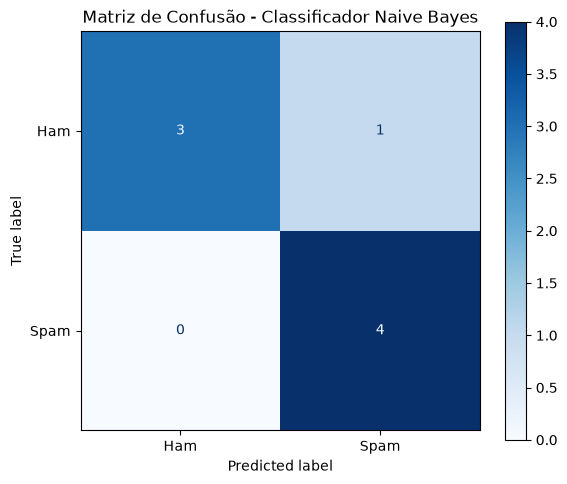

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# 1. Predição nas amostras de teste
y_pred = classificador_nb.predict(X_teste_vec)

# 2. Relatório Analítico Detalhado
print("=== RELATÓRIO DE CLASSIFICAÇÃO DETALHADO ===")
print(classification_report(y_teste, y_pred, target_names=["Ham (0)", "Spam (1)"], digits=4))

# 3. Matriz de Confusão Visual
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    classificador_nb,
    X_teste_vec,
    y_teste,
    display_labels=["Ham", "Spam"],
    cmap=plt.cm.Blues,
    ax=ax
)
ax.set_title("Matriz de Confusão - Classificador Naive Bayes")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.naive_bayes import BernoulliNB

# Treinamento do classificador Bernoulli
classificador_bernoulli = BernoulliNB(alpha=1.0)
classificador_bernoulli.fit(X_treino_vec, y_treino)

y_pred_bernoulli = classificador_bernoulli.predict(X_teste_vec)

print("=== RELATÓRIO: BERNOULLI NAIVE BAYES ===")
print(classification_report(y_teste, y_pred_bernoulli, target_names=["Ham (0)", "Spam (1)"]))

=== RELATÓRIO: BERNOULLI NAIVE BAYES ===
              precision    recall  f1-score   support

     Ham (0)       0.67      1.00      0.80         4
    Spam (1)       1.00      0.50      0.67         4

    accuracy                           0.75         8
   macro avg       0.83      0.75      0.73         8
weighted avg       0.83      0.75      0.73         8



Total de amostras: 1797
Total de características por amostra (pixels 8x8): 64
Classes disponíveis (dígitos de 0 a 9): [0 1 2 3 4 5 6 7 8 9]


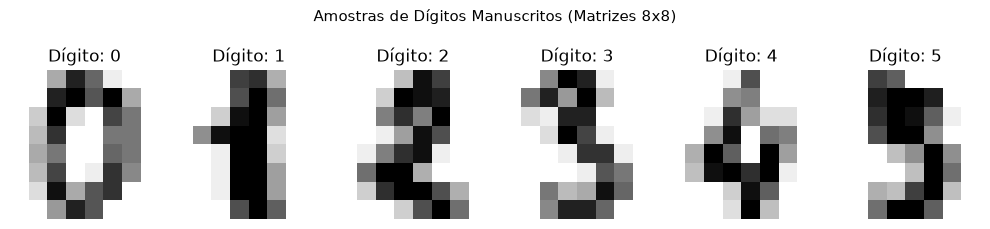


=== DESEMPENHO NO DATASET DE DÍGITOS (MULTICLASSE) ===
              precision    recall  f1-score   support

           0     1.0000    0.9630    0.9811        54
           1     0.7551    0.6727    0.7115        55
           2     0.8421    0.9057    0.8727        53
           3     0.9808    0.9273    0.9533        55
           4     0.9444    0.9444    0.9444        54
           5     0.9762    0.7455    0.8454        55
           6     0.9811    0.9630    0.9720        54
           7     0.8308    1.0000    0.9076        54
           8     0.7719    0.8462    0.8073        52
           9     0.7288    0.7963    0.7611        54

    accuracy                         0.8759       540
   macro avg     0.8811    0.8764    0.8756       540
weighted avg     0.8817    0.8759    0.8757       540



In [9]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report

# 1. Carregamento do dataset embutido
digitos = load_digits()
X_digitos, y_digitos = digitos.data, digitos.target

print(f"Total de amostras: {X_digitos.shape[0]}")
print(f"Total de características por amostra (pixels 8x8): {X_digitos.shape[1]}")
print(f"Classes disponíveis (dígitos de 0 a 9): {digitos.target_names}")

# 2. Visualização de uma linha de imagens (amostras de 0 a 5)
fig, axes = plt.subplots(1, 6, figsize=(10, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(digitos.images[i], cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"Dígito: {digitos.target[i]}")
    ax.axis("off")
plt.suptitle("Amostras de Dígitos Manuscritos (Matrizes 8x8)", fontsize=11)
plt.tight_layout()
plt.show()

# 3. Divisão estratificada (70% treino, 30% teste)
X_tr_dig, X_te_dig, y_tr_dig, y_te_dig = train_test_split(
    X_digitos,
    y_digitos,
    test_size=0.30,
    random_state=42,
    stratify=y_digitos
)

# 4. Treinamento com Multinomial Naive Bayes
classificador_digitos = MultinomialNB(alpha=1.0)
classificador_digitos.fit(X_tr_dig, y_tr_dig)

# 5. Avaliação do modelo multiclasse
y_pred_dig = classificador_digitos.predict(X_te_dig)

print("\n=== DESEMPENHO NO DATASET DE DÍGITOS (MULTICLASSE) ===")
print(classification_report(y_te_dig, y_pred_dig, digits=4))

In [10]:
from sklearn.pipeline import Pipeline

# 1. Construção do Pipeline (Vetorização + Classificador)
pipeline_spam = Pipeline([
    ("vetorizador", CountVectorizer(lowercase=True, stop_words=stop_words_pt)),
    ("classificador", MultinomialNB(alpha=1.0))
])

# 2. Treinamento direto nos textos brutos de treino
pipeline_spam.fit(X_treino_raw, y_treino)

print("Pipeline treinado com sucesso!")

# 3. Avaliação direta nos textos brutos de teste
y_pred_pipe = pipeline_spam.predict(X_teste_raw)

print("\n=== AVALIAÇÃO VIA PIPELINE ===")
print(classification_report(y_teste, y_pred_pipe, target_names=["Ham", "Spam"]))

# 4. Inferência direta em novos textos livres
novas_mensagens = [
    "Parabéns! Você ganhou um voucher exclusivo para compras via PIX.",
    "Reunião de alinhamento com a equipe reagendada para amanhã cedo.",
    "Aviso da sua conta bancária: fatura vencida disponível para pagamento imediato."
]

previsoes_pipe = pipeline_spam.predict(novas_mensagens)
probabilidades_pipe = pipeline_spam.predict_proba(novas_mensagens)

print("-" * 80)
for msg, pred, prob in zip(novas_mensagens, previsoes_pipe, probabilidades_pipe):
    rotulo = "Spam" if pred == 1 else "Legítimo (Ham)"
    confianca = prob[pred] * 100
    print(f"Texto: '{msg}'")
    print(f"Classificação: {rotulo} (Confiança: {confianca:.2f}%)")
    print("-" * 80)

Pipeline treinado com sucesso!

=== AVALIAÇÃO VIA PIPELINE ===
              precision    recall  f1-score   support

         Ham       1.00      0.75      0.86         4
        Spam       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8

--------------------------------------------------------------------------------
Texto: 'Parabéns! Você ganhou um voucher exclusivo para compras via PIX.'
Classificação: Spam (Confiança: 98.44%)
--------------------------------------------------------------------------------
Texto: 'Reunião de alinhamento com a equipe reagendada para amanhã cedo.'
Classificação: Legítimo (Ham) (Confiança: 97.11%)
--------------------------------------------------------------------------------
Texto: 'Aviso da sua conta bancária: fatura vencida disponível para pagamento imediato.'
Classificação: Spam (Confiança: 77.17%)
